<a href="https://colab.research.google.com/github/RohanSNikam/Logistics-Delivery-Time-Analysis/blob/main/notebooks/Week_3_logistics_delivery_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving Week2_Logistics_Preprocessed.xlsx to Week2_Logistics_Preprocessed.xlsx


In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

In [ ]:
df = pd.read_excel(
    'Week2_Logistics_Preprocessed.xlsx',
    sheet_name='Cleaned_Data'
)

In [ ]:
df.head()

,order_id,order_date,origin_city,destination_city,distance_km,traffic_level,weather,vehicle_type,order_value_inr,promised_delivery_minutes,actual_delivery_minutes,delivery_cost_inr,delivery_status,inventory_qty,year,month,day
0,LOG100555,2026-01-15,Nashik,Nagpur,105.5,High,Clear,Bike,13550.21,180,203.0,535.34,Delayed,19.0,2026,1,15
1,LOG100331,2026-01-13,Satara,Aurangabad,440.2,Medium,Clear,Truck,5898.03,541,602.0,1337.10,Delayed,103.0,2026,1,13
2,LOG100974,2026-07-20,Satara,Aurangabad,19.1,Medium,Foggy,Van,20909.87,388,459.0,241.92,Delayed,99.0,2026,7,20
3,LOG100157,2026-06-26,Ahmednagar,Mumbai,407.9,High,Clear,Bike,19699.13,486,552.0,1705.47,Delayed,78.0,2026,6,26
4,LOG100322,2026-10-04,Satara,Thane,234.2,Medium,Clear,Truck,4527.08,342,455.0,826.18,Delayed,76.0,2026,10,4


In [ ]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 985
Number of Columns: 17


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 985 entries, 0 to 984
Data columns (total 17 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   order_id                   985 non-null    object        
 1   order_date                 985 non-null    datetime64[ns]
 2   origin_city                985 non-null    object        
 3   destination_city           985 non-null    object        
 4   distance_km                985 non-null    float64       
 5   traffic_level              985 non-null    object        
 6   weather                    985 non-null    object        
 7   vehicle_type               985 non-null    object        
 8   order_value_inr            985 non-null    float64       
 9   promised_delivery_minutes  985 non-null    int64         
 10  actual_delivery_minutes    985 non-null    float64       
 11  delivery_cost_inr          985 non-null    float64       
 12  delivery

In [ ]:
df.columns

Index(['order_id', 'order_date', 'origin_city', 'destination_city',
       'distance_km', 'traffic_level', 'weather', 'vehicle_type',
       'order_value_inr', 'promised_delivery_minutes',
       'actual_delivery_minutes', 'delivery_cost_inr', 'delivery_status',
       'inventory_qty', 'year', 'month', 'day'],
      dtype='object')

In [ ]:
df.head()

,order_id,order_date,origin_city,destination_city,distance_km,traffic_level,weather,vehicle_type,order_value_inr,promised_delivery_minutes,actual_delivery_minutes,delivery_cost_inr,delivery_status,inventory_qty,year,month,day
0,LOG100555,2026-01-15,Nashik,Nagpur,105.5,High,Clear,Bike,13550.21,180,203.0,535.34,Delayed,19.0,2026,1,15
1,LOG100331,2026-01-13,Satara,Aurangabad,440.2,Medium,Clear,Truck,5898.03,541,602.0,1337.10,Delayed,103.0,2026,1,13
2,LOG100974,2026-07-20,Satara,Aurangabad,19.1,Medium,Foggy,Van,20909.87,388,459.0,241.92,Delayed,99.0,2026,7,20
3,LOG100157,2026-06-26,Ahmednagar,Mumbai,407.9,High,Clear,Bike,19699.13,486,552.0,1705.47,Delayed,78.0,2026,6,26
4,LOG100322,2026-10-04,Satara,Thane,234.2,Medium,Clear,Truck,4527.08,342,455.0,826.18,Delayed,76.0,2026,10,4


In [ ]:
df.tail()

,order_id,order_date,origin_city,destination_city,distance_km,traffic_level,weather,vehicle_type,order_value_inr,promised_delivery_minutes,actual_delivery_minutes,delivery_cost_inr,delivery_status,inventory_qty,year,month,day
980,LOG100985,2026-06-02,Satara,Aurangabad,294.9,Low,Rainy,Tempo,10926.24,515,663.0,1432.85,Delayed,11.0,2026,6,2
981,LOG100844,2026-02-27,Nashik,Satara,218.4,High,Rainy,Van,16573.54,458,974.0,891.13,Delayed,121.0,2026,2,27
982,LOG100862,2026-02-15,Ahmednagar,Thane,299.9,High,Cloudy,Tempo,15266.44,100,161.0,1276.27,Delayed,8.0,2026,2,15
983,LOG100692,2026-06-24,Aurangabad,Ahmednagar,223.8,High,Rainy,Bike,19421.10,154,333.0,912.55,Delayed,108.0,2026,6,24
984,LOG100778,2026-01-23,Solapur,Mumbai,269.6,High,Clear,Bike,11852.39,810,1079.0,1337.86,Delayed,90.0,2026,1,23


In [ ]:
df.isnull().sum()

,0
order_id,0
order_date,0
origin_city,0
destination_city,0
distance_km,0
traffic_level,0
weather,0
vehicle_type,0
order_value_inr,0
promised_delivery_minutes,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
numerical_cols = df.select_dtypes(
    include=['int64', 'float64']
).columns

categorical_cols = df.select_dtypes(
    include=['object', 'category']
).columns

print("Numerical Columns:")
print(numerical_cols)

print("\nCategorical Columns:")
print(categorical_cols)

Numerical Columns:
Index(['distance_km', 'order_value_inr', 'promised_delivery_minutes',
       'actual_delivery_minutes', 'delivery_cost_inr', 'inventory_qty', 'year',
       'month', 'day'],
      dtype='object')

Categorical Columns:
Index(['order_id', 'origin_city', 'destination_city', 'traffic_level',
       'weather', 'vehicle_type', 'delivery_status'],
      dtype='object')


In [ ]:
for col in categorical_cols:
    print("\nColumn:", col)
    print(df[col].unique())


Column: order_id
['LOG100555' 'LOG100331' 'LOG100974' 'LOG100157' 'LOG100322' 'LOG100913'
 'LOG100593' 'LOG100854' 'LOG100905' 'LOG100473' 'LOG100488' 'LOG100903'
 'LOG100081' 'LOG100944' 'LOG100328' 'LOG100879' 'LOG100012' 'LOG100419'
 'LOG100373' 'LOG100795' 'LOG100454' 'LOG100949' 'LOG100386' 'LOG100736'
 'LOG100167' 'LOG100554' 'LOG100804' 'LOG100726' 'LOG100904' 'LOG100191'
 'LOG100557' 'LOG100872' 'LOG100823' 'LOG100827' 'LOG100719' 'LOG100351'
 'LOG100757' 'LOG100800' 'LOG100222' 'LOG100180' 'LOG100568' 'LOG100257'
 'LOG100671' 'LOG100150' 'LOG100175' 'LOG100200' 'LOG100128' 'LOG100759'
 'LOG100694' 'LOG100208' 'LOG100333' 'LOG100348' 'LOG100612' 'LOG100766'
 'LOG100662' 'LOG100016' 'LOG100075' 'LOG100439' 'LOG100561' 'LOG100370'
 'LOG100664' 'LOG100941' 'LOG100276' 'LOG100840' 'LOG100785' 'LOG100760'
 'LOG100727' 'LOG100796' 'LOG100754' 'LOG100135' 'LOG100870' 'LOG100761'
 'LOG100864' 'LOG100108' 'LOG100538' 'LOG100221' 'LOG100152' 'LOG100943'
 'LOG100897' 'LOG100980' 'LOG1005

In [ ]:
df['distance_km'].mean()

np.float64(265.088730964467)

In [ ]:
df['distance_km'].median()

276.8

In [ ]:
df['distance_km'].mode()[0]

np.float64(276.8)

In [ ]:
df['distance_km'].var()

20623.972418611484

In [ ]:
df['distance_km'].std()

143.6104885397006

In [ ]:
df.describe()

,order_date,distance_km,order_value_inr,promised_delivery_minutes,actual_delivery_minutes,delivery_cost_inr,inventory_qty,year,month,day
count,985,985.000000,985.000000,985.000000,985.000000,985.000000,985.000000,985.0,985.000000,985.000000
mean,2026-06-03 09:37:27.715736064,265.088731,12036.412985,493.669036,625.486802,1086.689716,74.797462,2026.0,5.603046,15.277157
min,2026-01-01 00:00:00,5.000000,276.890000,60.000000,5.000000,5.000000,0.000000,2026.0,1.000000,1.000000
25%,2026-03-19 00:00:00,141.400000,5700.420000,285.000000,342.000000,626.330000,39.000000,2026.0,3.000000,8.000000
50%,2026-06-10 00:00:00,276.800000,11505.710000,501.000000,586.000000,1085.590000,75.000000,2026.0,6.000000,15.000000
75%,2026-08-15 00:00:00,385.900000,18200.280000,711.000000,865.000000,1450.300000,112.000000,2026.0,8.000000,23.000000
max,2026-10-27 00:00:00,752.650000,24988.840000,896.000000,1649.500000,2686.255000,221.500000,2026.0,10.000000,31.000000
std,NaN,143.610489,7202.635962,242.841730,358.249882,552.610651,42.795100,0.0,2.840222,8.693361


In [ ]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
order_date,985,2026-06-03 09:37:27.715736064,2026-01-01 00:00:00,2026-03-19 00:00:00,2026-06-10 00:00:00,2026-08-15 00:00:00,2026-10-27 00:00:00,NaN
distance_km,985.0,265.088731,5.0,141.4,276.8,385.9,752.65,143.610489
order_value_inr,985.0,12036.412985,276.89,5700.42,11505.71,18200.28,24988.84,7202.635962
promised_delivery_minutes,985.0,493.669036,60.0,285.0,501.0,711.0,896.0,242.84173
actual_delivery_minutes,985.0,625.486802,5.0,342.0,586.0,865.0,1649.5,358.249882
delivery_cost_inr,985.0,1086.689716,5.0,626.33,1085.59,1450.3,2686.255,552.610651
inventory_qty,985.0,74.797462,0.0,39.0,75.0,112.0,221.5,42.7951
year,985.0,2026.0,2026.0,2026.0,2026.0,2026.0,2026.0,0.0
month,985.0,5.603046,1.0,3.0,6.0,8.0,10.0,2.840222
day,985.0,15.277157,1.0,8.0,15.0,23.0,31.0,8.693361


In [ ]:
analysis_cols = [
    'distance_km',
    'order_value_inr',
    'promised_delivery_minutes',
    'actual_delivery_minutes',
    'delivery_cost_inr',
    'inventory_qty'
]

summary = pd.DataFrame({
    'Mean': df[analysis_cols].mean(),
    'Median': df[analysis_cols].median(),
    'Standard Deviation': df[analysis_cols].std(),
    'Minimum': df[analysis_cols].min(),
    'Maximum': df[analysis_cols].max()
})

summary

,Mean,Median,Standard Deviation,Minimum,Maximum
distance_km,265.088731,276.80,143.610489,5.00,752.650
order_value_inr,12036.412985,11505.71,7202.635962,276.89,24988.840
promised_delivery_minutes,493.669036,501.00,242.841730,60.00,896.000
actual_delivery_minutes,625.486802,586.00,358.249882,5.00,1649.500
delivery_cost_inr,1086.689716,1085.59,552.610651,5.00,2686.255
inventory_qty,74.797462,75.00,42.795100,0.00,221.500


In [ ]:
analysis_cols = [
    'distance_km',
    'order_value_inr',
    'promised_delivery_minutes',
    'actual_delivery_minutes',
    'delivery_cost_inr',
    'inventory_qty'
]

summary = pd.DataFrame({
    'Mean': df[analysis_cols].mean(),
    'Median': df[analysis_cols].median(),
    'Standard Deviation': df[analysis_cols].std(),
    'Minimum': df[analysis_cols].min(),
    'Maximum': df[analysis_cols].max()
})

summary

,Mean,Median,Standard Deviation,Minimum,Maximum
distance_km,265.088731,276.80,143.610489,5.00,752.650
order_value_inr,12036.412985,11505.71,7202.635962,276.89,24988.840
promised_delivery_minutes,493.669036,501.00,242.841730,60.00,896.000
actual_delivery_minutes,625.486802,586.00,358.249882,5.00,1649.500
delivery_cost_inr,1086.689716,1085.59,552.610651,5.00,2686.255
inventory_qty,74.797462,75.00,42.795100,0.00,221.500


In [ ]:
df['delay_minutes'] = (
    df['actual_delivery_minutes'] -
    df['promised_delivery_minutes']
)

In [ ]:
df['performance_status'] = np.where(
    df['actual_delivery_minutes'] <=
    df['promised_delivery_minutes'],
    'On-Time',
    'Delayed'
)

In [ ]:
df['performance_status'].value_counts()

,count
performance_status,
Delayed,764
On-Time,221


In [ ]:
rng = np.random.default_rng(42)

available_stock = (
    df['inventory_qty']
    .fillna(0)
    .clip(lower=0)
    .astype(int)
)

simulated_demand = rng.integers(
    1, 31, size=len(df)
)

df['shipment_volume_units'] = np.minimum(
    available_stock,
    simulated_demand
)

In [ ]:
df[
    ['inventory_qty', 'shipment_volume_units']
].head(10)

,inventory_qty,shipment_volume_units
0,19.0,3
1,103.0,24
2,99.0,20
3,78.0,14
4,76.0,13
5,112.0,26
6,64.0,3
7,84.0,21
8,80.0,7
9,130.0,3


In [ ]:
df['late_minutes'] = (
    df['delay_minutes'].clip(lower=0)
)

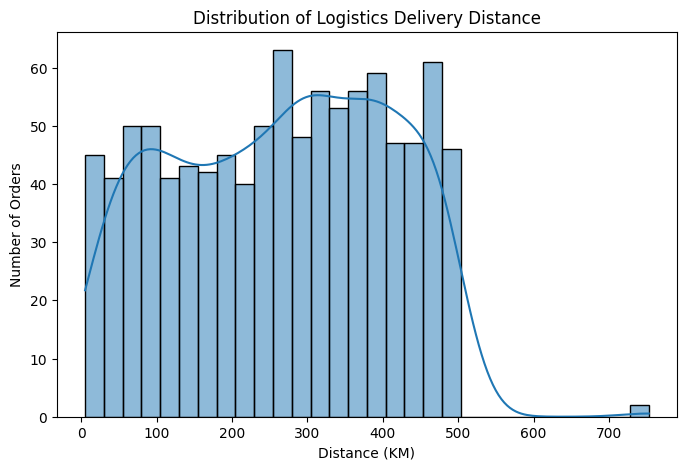

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x='distance_km',
    bins=30,
    kde=True
)

plt.title('Distribution of Logistics Delivery Distance')
plt.xlabel('Distance (KM)')
plt.ylabel('Number of Orders')

plt.show()

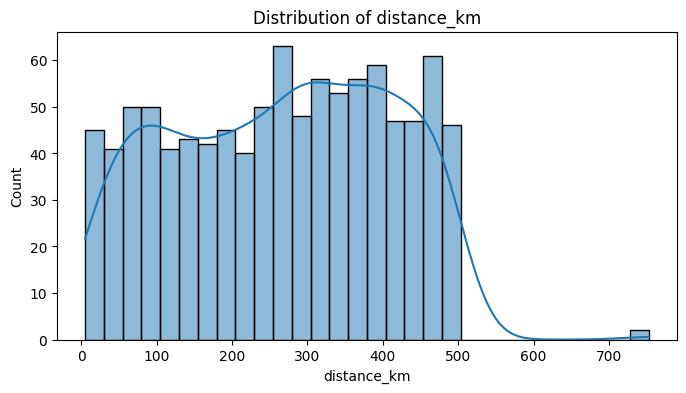

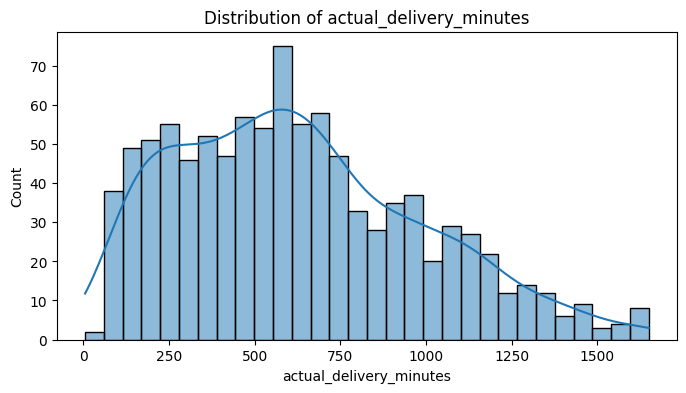

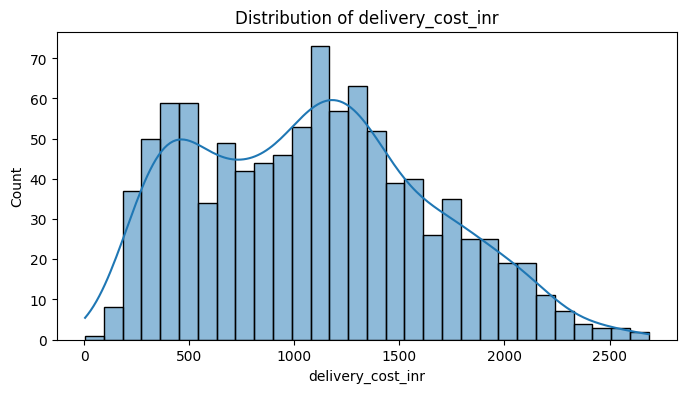

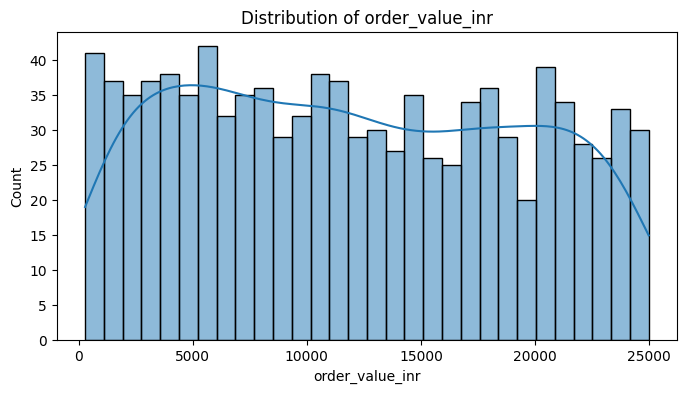

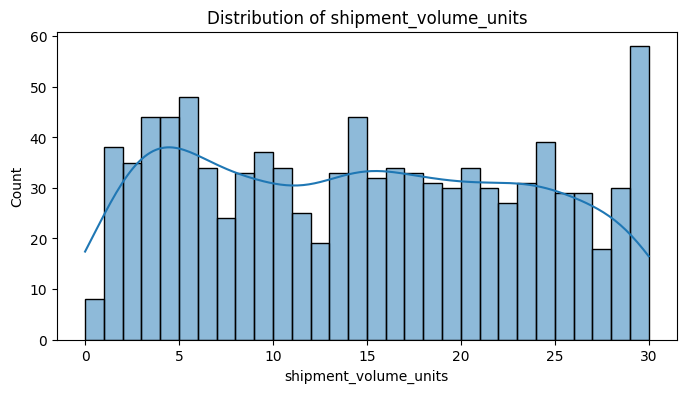

In [ ]:
hist_cols = [
    'distance_km',
    'actual_delivery_minutes',
    'delivery_cost_inr',
    'order_value_inr',
    'shipment_volume_units'
]

for col in hist_cols:

    plt.figure(figsize=(8, 4))

    sns.histplot(
        data=df,
        x=col,
        bins=30,
        kde=True
    )

    plt.title(f'Distribution of {col}')
    plt.show()

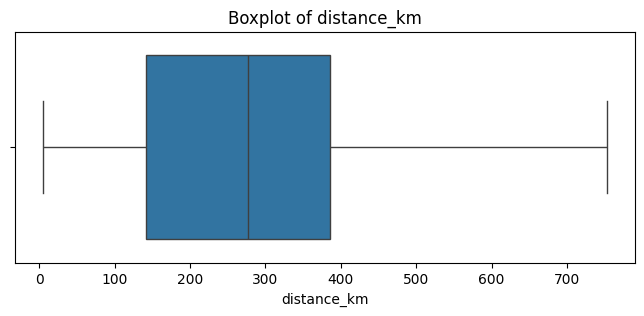

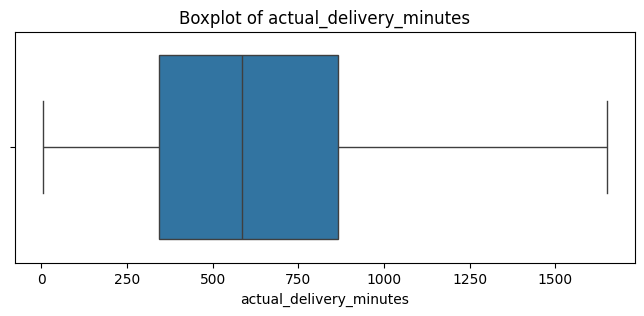

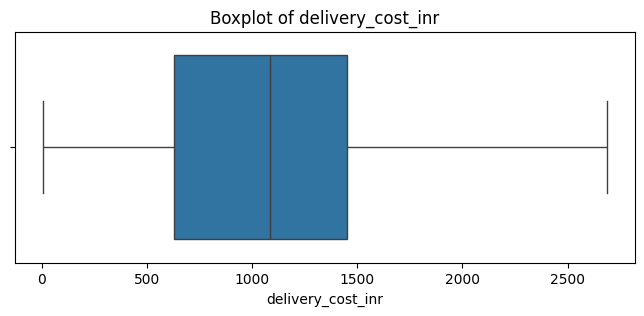

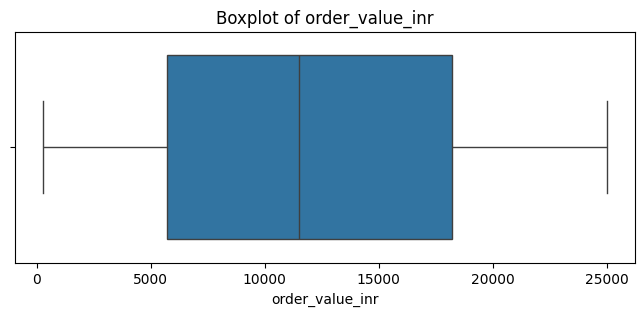

In [ ]:
box_cols = [
    'distance_km',
    'actual_delivery_minutes',
    'delivery_cost_inr',
    'order_value_inr'
]

for col in box_cols:

    plt.figure(figsize=(8, 3))

    sns.boxplot(x=df[col])

    plt.title(f'Boxplot of {col}')

    plt.show()

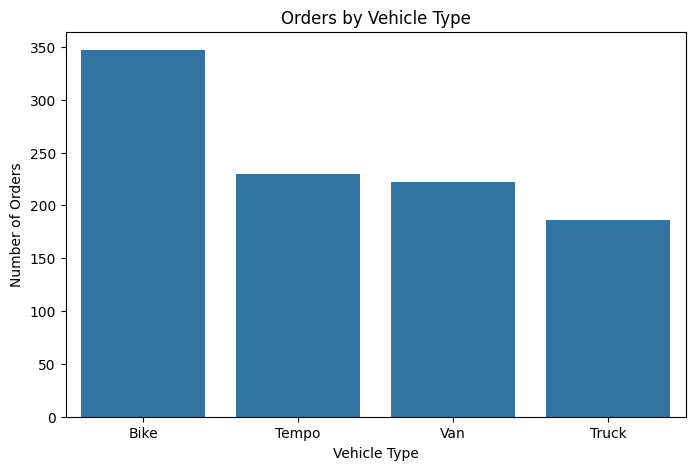

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='vehicle_type',
    order=df['vehicle_type'].value_counts().index
)

plt.title('Orders by Vehicle Type')
plt.xlabel('Vehicle Type')
plt.ylabel('Number of Orders')

plt.show()

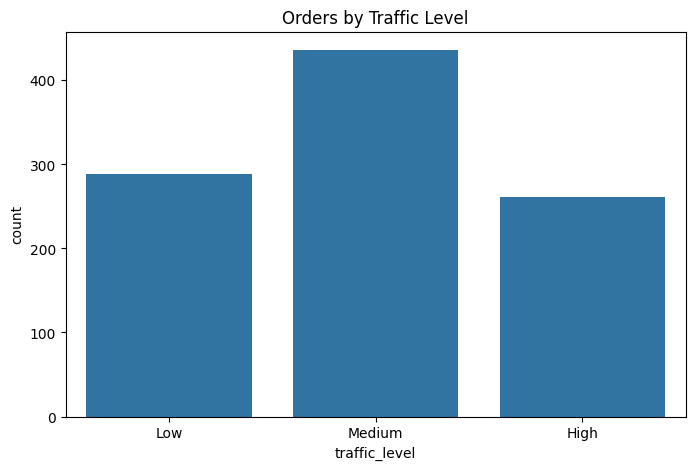

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='traffic_level',
    order=['Low', 'Medium', 'High']
)

plt.title('Orders by Traffic Level')
plt.show()

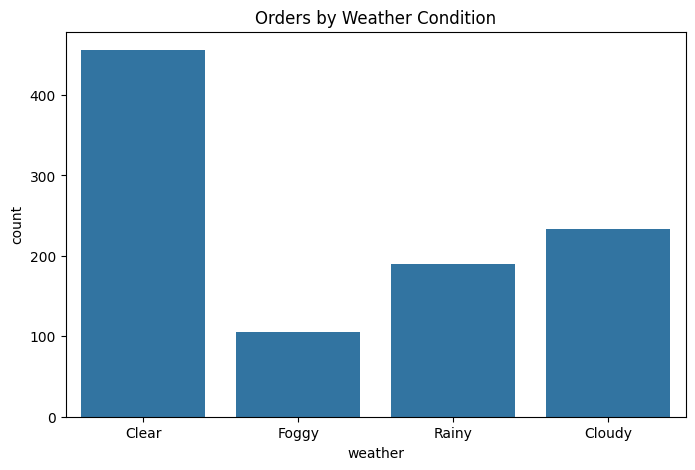

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='weather'
)

plt.title('Orders by Weather Condition')
plt.show()

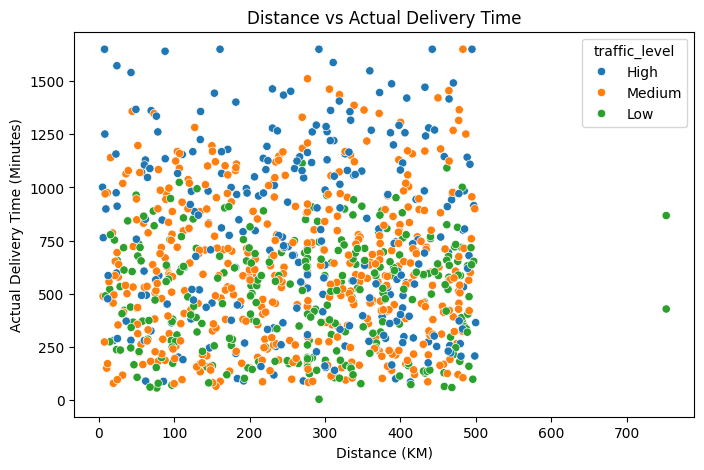

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='distance_km',
    y='actual_delivery_minutes',
    hue='traffic_level'
)

plt.title('Distance vs Actual Delivery Time')
plt.xlabel('Distance (KM)')
plt.ylabel('Actual Delivery Time (Minutes)')

plt.show()

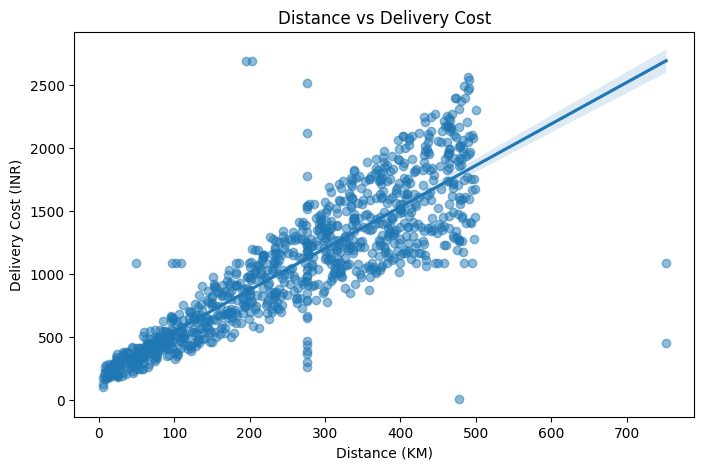

In [ ]:
plt.figure(figsize=(8, 5))

sns.regplot(
    data=df,
    x='distance_km',
    y='delivery_cost_inr',
    scatter_kws={'alpha': 0.5}
)

plt.title('Distance vs Delivery Cost')
plt.xlabel('Distance (KM)')
plt.ylabel('Delivery Cost (INR)')

plt.show()

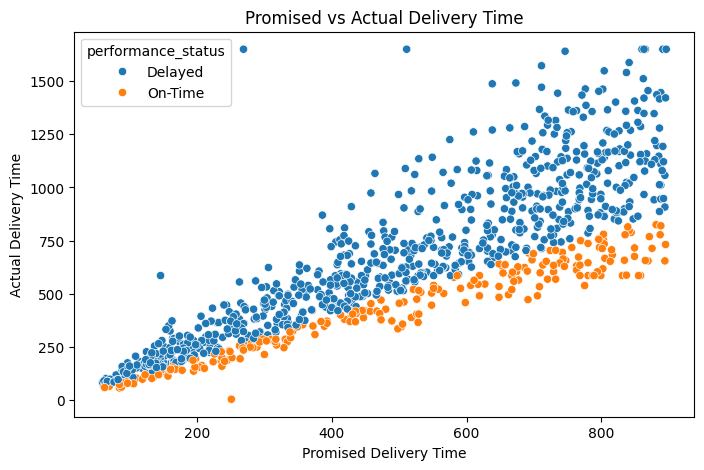

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='promised_delivery_minutes',
    y='actual_delivery_minutes',
    hue='performance_status'
)

plt.title('Promised vs Actual Delivery Time')
plt.xlabel('Promised Delivery Time')
plt.ylabel('Actual Delivery Time')

plt.show()

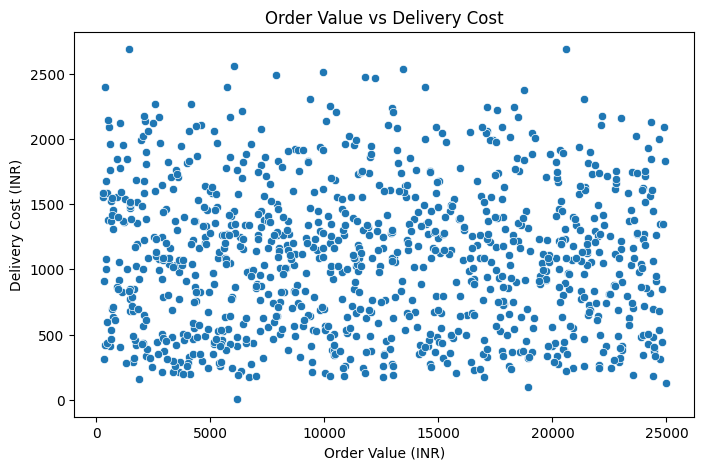

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='order_value_inr',
    y='delivery_cost_inr'
)

plt.title('Order Value vs Delivery Cost')
plt.xlabel('Order Value (INR)')
plt.ylabel('Delivery Cost (INR)')

plt.show()

In [ ]:
total_orders = len(df)

on_time_orders = (
    df['performance_status'] == 'On-Time'
).sum()

delayed_orders = (
    df['performance_status'] == 'Delayed'
).sum()

on_time_rate = (
    on_time_orders / total_orders
) * 100

delay_rate = (
    delayed_orders / total_orders
) * 100

print("Total Orders:", total_orders)
print("On-Time Orders:", on_time_orders)
print("Delayed Orders:", delayed_orders)

print("On-Time Rate:", round(on_time_rate, 2), "%")
print("Delay Rate:", round(delay_rate, 2), "%")

Total Orders: 985
On-Time Orders: 221
Delayed Orders: 764
On-Time Rate: 22.44 %
Delay Rate: 77.56 %


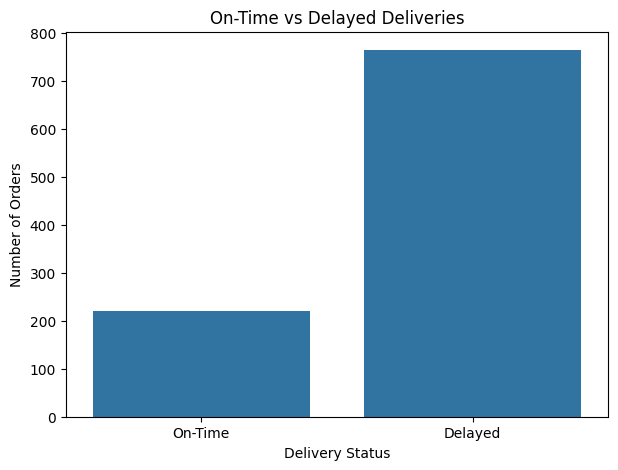

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='performance_status',
    order=['On-Time', 'Delayed']
)

plt.title('On-Time vs Delayed Deliveries')
plt.xlabel('Delivery Status')
plt.ylabel('Number of Orders')

plt.show()

In [ ]:
vehicle_perf = df.groupby(
    'vehicle_type'
).agg(
    total_orders=('order_id', 'count'),
    avg_delivery_time=('actual_delivery_minutes', 'mean'),
    avg_delivery_cost=('delivery_cost_inr', 'mean'),
    on_time_rate=('performance_status',
                  lambda x: (x == 'On-Time').mean() * 100)
).reset_index()

vehicle_perf

,vehicle_type,total_orders,avg_delivery_time,avg_delivery_cost,on_time_rate
0,Bike,347,632.828530,1087.816916,23.054755
1,Tempo,230,636.984783,1099.491283,20.434783
2,Truck,186,630.338710,1086.132419,22.580645
3,Van,222,598.033784,1072.131869,23.423423


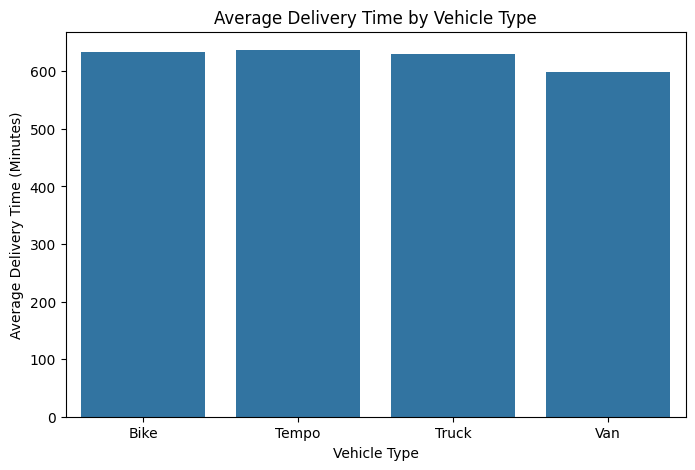

In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=vehicle_perf,
    x='vehicle_type',
    y='avg_delivery_time'
)

plt.title('Average Delivery Time by Vehicle Type')
plt.xlabel('Vehicle Type')
plt.ylabel('Average Delivery Time (Minutes)')

plt.show()

In [ ]:
traffic_perf = df.groupby(
    'traffic_level'
).agg(
    total_orders=('order_id', 'count'),
    avg_delivery_time=('actual_delivery_minutes', 'mean'),
    avg_delivery_cost=('delivery_cost_inr', 'mean'),
    on_time_rate=('performance_status',
                  lambda x: (x == 'On-Time').mean() * 100)
).reindex(['Low', 'Medium', 'High']).reset_index()

traffic_perf

,traffic_level,total_orders,avg_delivery_time,avg_delivery_cost,on_time_rate
0,Low,288,493.322917,1131.909080,55.555556
1,Medium,436,613.724771,1055.741204,13.761468
2,High,261,790.971264,1088.491916,0.383142


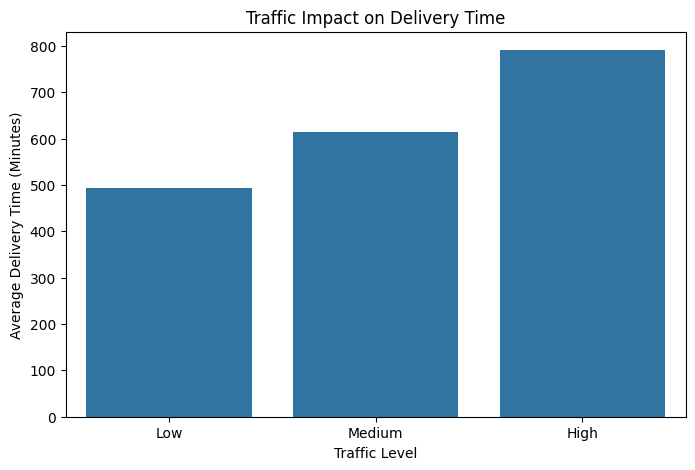

In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=traffic_perf,
    x='traffic_level',
    y='avg_delivery_time'
)

plt.title('Traffic Impact on Delivery Time')
plt.xlabel('Traffic Level')
plt.ylabel('Average Delivery Time (Minutes)')

plt.show()

In [ ]:
weather_perf = df.groupby(
    'weather'
).agg(
    total_orders=('order_id', 'count'),
    avg_delivery_time=('actual_delivery_minutes', 'mean'),
    on_time_rate=('performance_status',
                  lambda x: (x == 'On-Time').mean() * 100)
).reset_index()

weather_perf

,weather,total_orders,avg_delivery_time,on_time_rate
0,Clear,456,576.846491,30.482456
1,Cloudy,234,592.594017,23.931624
2,Foggy,105,713.071429,7.619048
3,Rainy,190,734.331579,9.473684


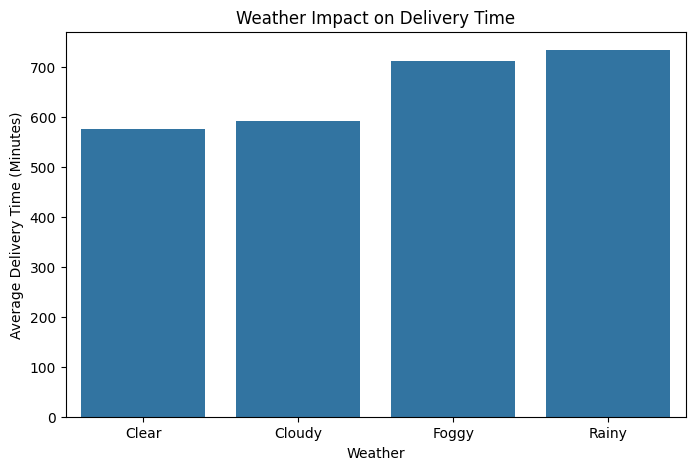

In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=weather_perf,
    x='weather',
    y='avg_delivery_time'
)

plt.title('Weather Impact on Delivery Time')
plt.xlabel('Weather')
plt.ylabel('Average Delivery Time (Minutes)')

plt.show()

In [ ]:
df['distance_category'] = pd.cut(
    df['distance_km'],
    bins=[0, 50, 100, 250, 500, np.inf],
    labels=[
        '0-50 KM',
        '51-100 KM',
        '101-250 KM',
        '251-500 KM',
        'Above 500 KM'
    ],
    include_lowest=True
)

In [ ]:
df['distance_category'].value_counts().sort_index()

,count
distance_category,
0-50 KM,73
51-100 KM,105
101-250 KM,264
251-500 KM,541
Above 500 KM,2


In [ ]:
distance_analysis = df.groupby(
    'distance_category',
    observed=False
).agg(
    total_orders=('order_id', 'count'),
    avg_delivery_time=('actual_delivery_minutes', 'mean'),
    avg_delivery_cost=('delivery_cost_inr', 'mean'),
    on_time_rate=('performance_status',
                  lambda x: (x == 'On-Time').mean() * 100)
).reset_index()

distance_analysis

,distance_category,total_orders,avg_delivery_time,avg_delivery_cost,on_time_rate
0,0-50 KM,73,643.513699,273.426575,21.917808
1,51-100 KM,105,586.200000,440.009714,22.857143
2,101-250 KM,264,629.626894,801.715114,21.590909
3,251-500 KM,541,628.573937,1462.175342,22.920518
4,Above 500 KM,2,648.500000,769.280000,0.000000


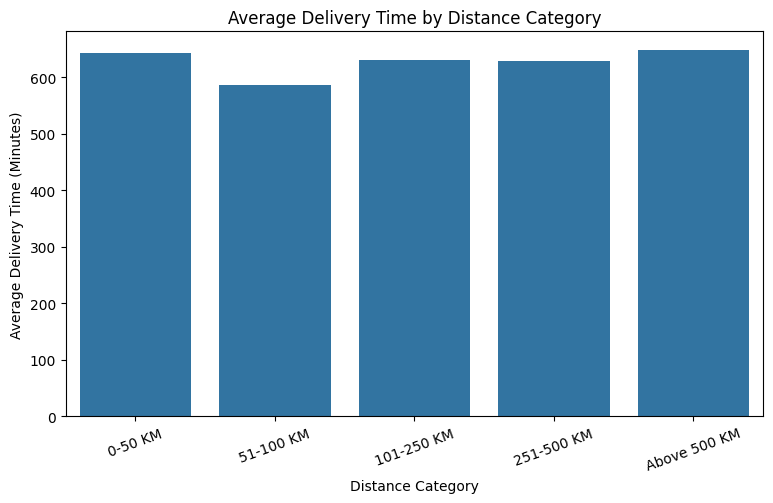

In [ ]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=distance_analysis,
    x='distance_category',
    y='avg_delivery_time'
)

plt.title('Average Delivery Time by Distance Category')
plt.xlabel('Distance Category')
plt.ylabel('Average Delivery Time (Minutes)')
plt.xticks(rotation=20)

plt.show()

In [ ]:
volume_analysis = df.groupby(
    'vehicle_type'
).agg(
    total_shipment_units=('shipment_volume_units', 'sum'),
    avg_shipment_units=('shipment_volume_units', 'mean'),
    total_orders=('order_id', 'count')
).reset_index()

volume_analysis

,vehicle_type,total_shipment_units,avg_shipment_units,total_orders
0,Bike,5153,14.850144,347
1,Tempo,3089,13.430435,230
2,Truck,2737,14.715054,186
3,Van,3315,14.932432,222


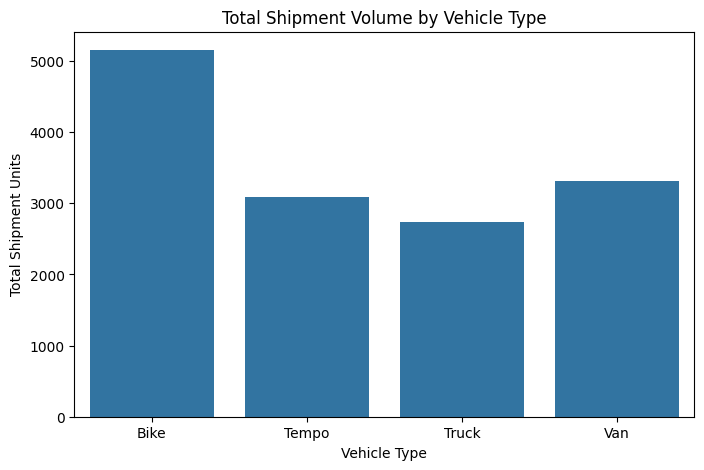

In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=volume_analysis,
    x='vehicle_type',
    y='total_shipment_units'
)

plt.title('Total Shipment Volume by Vehicle Type')
plt.xlabel('Vehicle Type')
plt.ylabel('Total Shipment Units')

plt.show()

In [ ]:
df['order_date'] = pd.to_datetime(
    df['order_date'],
    errors='coerce'
)

In [ ]:
df['month_year'] = (
    df['order_date'].dt.to_period('M').astype(str)
)

In [ ]:
monthly_analysis = df.groupby(
    'month_year'
).agg(
    total_orders=('order_id', 'count'),
    avg_delivery_time=('actual_delivery_minutes', 'mean'),
    avg_delivery_cost=('delivery_cost_inr', 'mean'),
    on_time_rate=('performance_status',
                  lambda x: (x == 'On-Time').mean() * 100)
).reset_index()

monthly_analysis

,month_year,total_orders,avg_delivery_time,avg_delivery_cost,on_time_rate
0,2026-01,97,608.159794,1050.264639,21.649485
1,2026-02,89,729.814607,1123.209551,16.853933
2,2026-03,96,577.072917,1041.277604,28.125000
3,2026-04,92,617.076087,1182.391848,27.173913
4,2026-05,91,606.373626,1108.120549,21.978022
5,2026-06,99,582.787879,1101.486061,22.222222
6,2026-07,103,670.077670,1094.143883,28.155340
7,2026-08,132,617.068182,1044.328258,20.454545
8,2026-09,98,610.153061,1124.926990,19.387755
9,2026-10,88,645.994318,1012.821193,18.181818


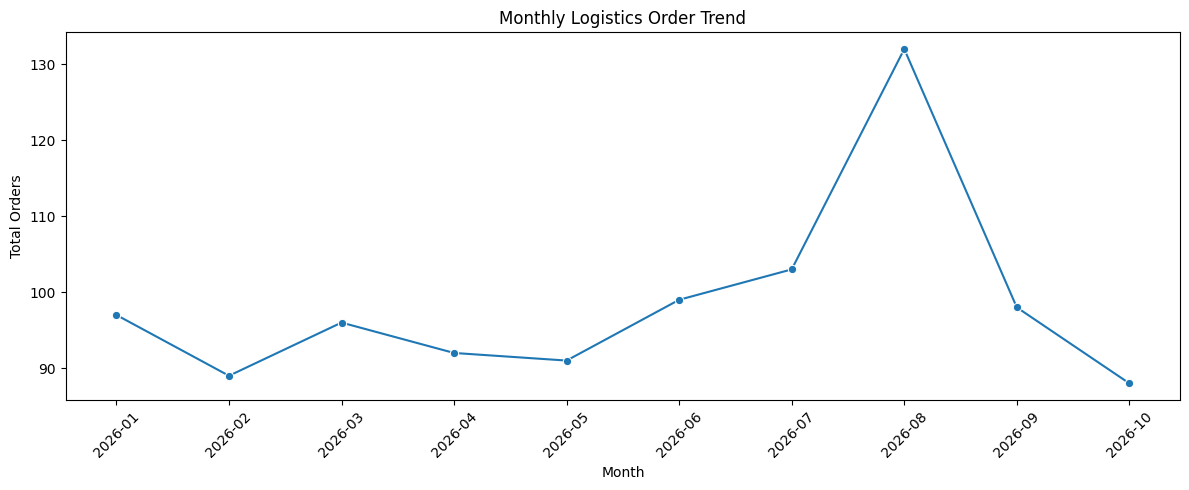

In [ ]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_analysis,
    x='month_year',
    y='total_orders',
    marker='o'
)

plt.title('Monthly Logistics Order Trend')
plt.xlabel('Month')
plt.ylabel('Total Orders')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

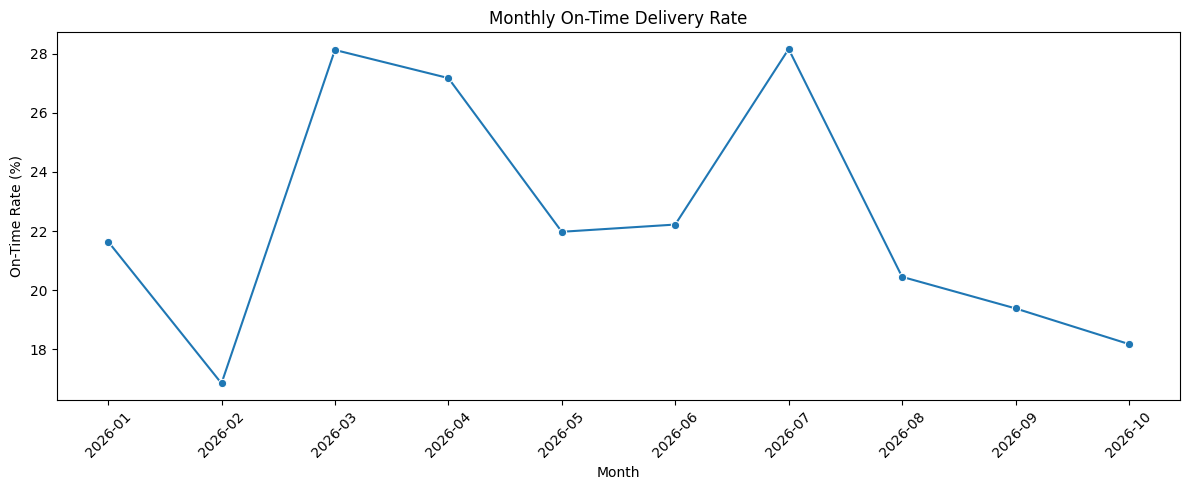

In [ ]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_analysis,
    x='month_year',
    y='on_time_rate',
    marker='o'
)

plt.title('Monthly On-Time Delivery Rate')
plt.xlabel('Month')
plt.ylabel('On-Time Rate (%)')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

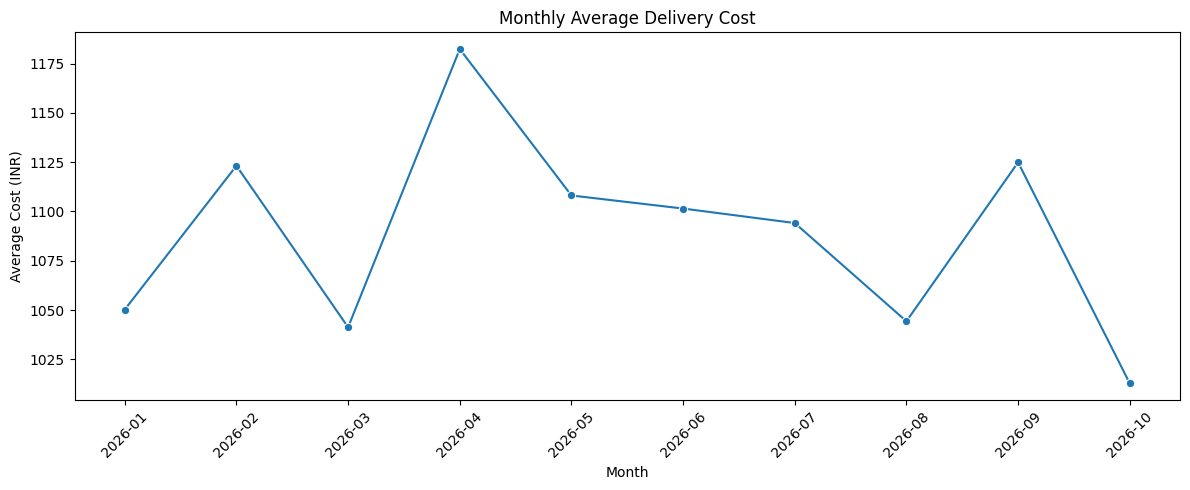

In [ ]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_analysis,
    x='month_year',
    y='avg_delivery_cost',
    marker='o'
)

plt.title('Monthly Average Delivery Cost')
plt.xlabel('Month')
plt.ylabel('Average Cost (INR)')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
correlation_cols = [
    'distance_km',
    'order_value_inr',
    'promised_delivery_minutes',
    'actual_delivery_minutes',
    'delivery_cost_inr',
    'inventory_qty',
    'shipment_volume_units',
    'delay_minutes'
]

correlation_matrix = df[
    correlation_cols
].corr(method='pearson')

correlation_matrix

,distance_km,order_value_inr,promised_delivery_minutes,actual_delivery_minutes,delivery_cost_inr,inventory_qty,shipment_volume_units,delay_minutes
distance_km,1.000000,-0.002539,0.006102,0.003871,0.855667,0.039743,-0.006133,-0.000478
order_value_inr,-0.002539,1.000000,0.009651,0.003131,-0.013754,-0.004517,0.006263,-0.006144
promised_delivery_minutes,0.006102,0.009651,1.000000,0.849174,-0.015124,0.030316,0.013701,0.308567
actual_delivery_minutes,0.003871,0.003131,0.849174,1.000000,-0.011646,0.007379,0.005733,0.764370
delivery_cost_inr,0.855667,-0.013754,-0.015124,-0.011646,1.000000,0.031603,-0.006848,-0.002511
inventory_qty,0.039743,-0.004517,0.030316,0.007379,0.031603,1.000000,0.228714,-0.023724
shipment_volume_units,-0.006133,0.006263,0.013701,0.005733,-0.006848,0.228714,1.000000,-0.006402
delay_minutes,-0.000478,-0.006144,0.308567,0.764370,-0.002511,-0.023724,-0.006402,1.000000


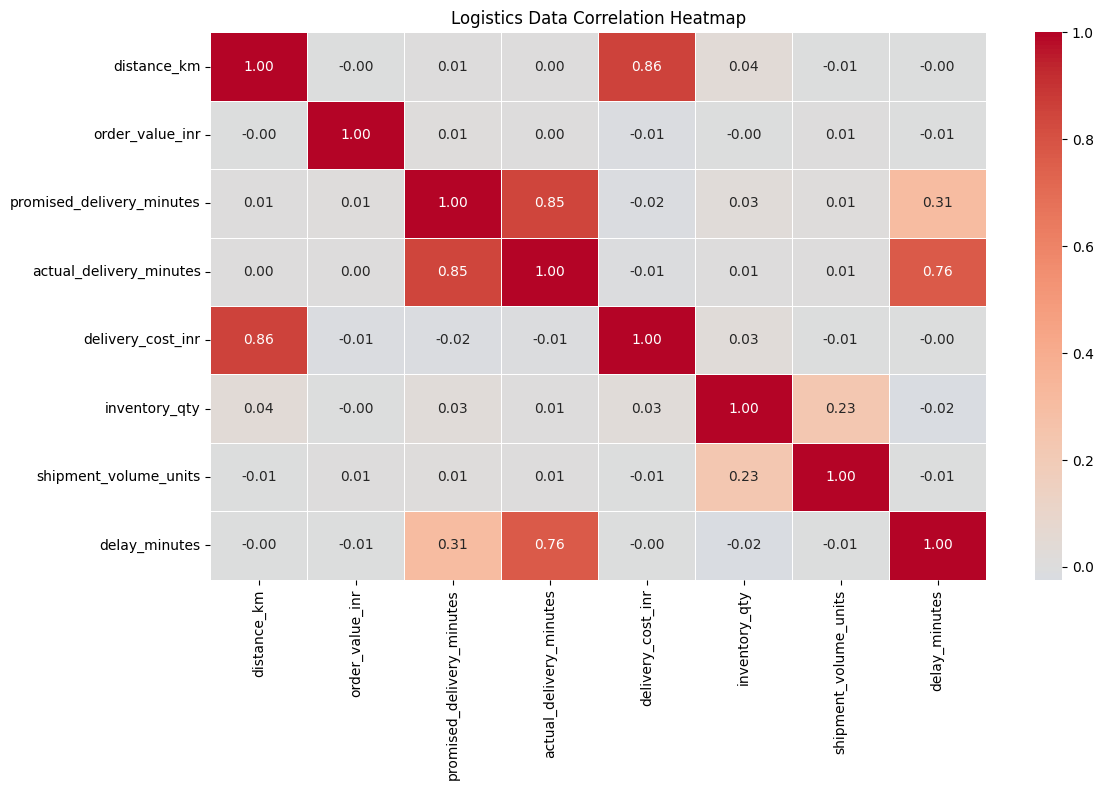

In [ ]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    center=0
)

plt.title('Logistics Data Correlation Heatmap')
plt.tight_layout()
plt.show()

In [ ]:
correlation_pairs = (
    correlation_matrix
    .where(
        np.triu(
            np.ones(correlation_matrix.shape),
            k=1
        ).astype(bool)
    )
    .stack()
    .sort_values(
        key=lambda x: x.abs(),
        ascending=False
    )
)

correlation_pairs.head(10)

,,0
distance_km,delivery_cost_inr,0.855667
promised_delivery_minutes,actual_delivery_minutes,0.849174
actual_delivery_minutes,delay_minutes,0.764370
promised_delivery_minutes,delay_minutes,0.308567
inventory_qty,shipment_volume_units,0.228714
distance_km,inventory_qty,0.039743
delivery_cost_inr,inventory_qty,0.031603
promised_delivery_minutes,inventory_qty,0.030316
inventory_qty,delay_minutes,-0.023724
promised_delivery_minutes,delivery_cost_inr,-0.015124


In [ ]:
highest_traffic_delay = traffic_perf.loc[
    traffic_perf['avg_delivery_time'].idxmax()
]

highest_traffic_delay

,2
traffic_level,High
total_orders,261
avg_delivery_time,790.971264
avg_delivery_cost,1088.491916
on_time_rate,0.383142


In [ ]:
highest_vehicle_cost = vehicle_perf.loc[
    vehicle_perf['avg_delivery_cost'].idxmax()
]

highest_vehicle_cost

,1
vehicle_type,Tempo
total_orders,230
avg_delivery_time,636.984783
avg_delivery_cost,1099.491283
on_time_rate,20.434783


In [ ]:
highest_weather_delay = weather_perf.loc[
    weather_perf['avg_delivery_time'].idxmax()
]

highest_weather_delay

,3
weather,Rainy
total_orders,190
avg_delivery_time,734.331579
on_time_rate,9.473684


In [ ]:
highest_distance_time = distance_analysis.loc[
    distance_analysis['avg_delivery_time'].idxmax()
]

highest_distance_time

,4
distance_category,Above 500 KM
total_orders,2
avg_delivery_time,648.5
avg_delivery_cost,769.28
on_time_rate,0.0


In [ ]:
best_vehicle = vehicle_perf.loc[
    vehicle_perf['on_time_rate'].idxmax()
]

best_vehicle

,3
vehicle_type,Van
total_orders,222
avg_delivery_time,598.033784
avg_delivery_cost,1072.131869
on_time_rate,23.423423


In [ ]:
highest_cost_month = monthly_analysis.loc[
    monthly_analysis['avg_delivery_cost'].idxmax()
]

highest_cost_month

,3
month_year,2026-04
total_orders,92
avg_delivery_time,617.076087
avg_delivery_cost,1182.391848
on_time_rate,27.173913


In [ ]:
kpis = {
    'Total Orders': len(df),

    'Average Distance (KM)': df['distance_km'].mean(),

    'Average Delivery Time (Minutes)':
        df['actual_delivery_minutes'].mean(),

    'Average Delivery Cost (INR)':
        df['delivery_cost_inr'].mean(),

    'On-Time Delivery Rate (%)':
        df['on_time_flag'].mean() * 100
        if 'on_time_flag' in df.columns
        else (df['performance_status'] == 'On-Time').mean() * 100,

    'Total Shipment Units':
        df['shipment_volume_units'].sum()
}

for name, value in kpis.items():
    print(name, ':', round(value, 2))

Total Orders : 985
Average Distance (KM) : 265.09
Average Delivery Time (Minutes) : 625.49
Average Delivery Cost (INR) : 1086.69
On-Time Delivery Rate (%) : 22.44
Total Shipment Units : 14294


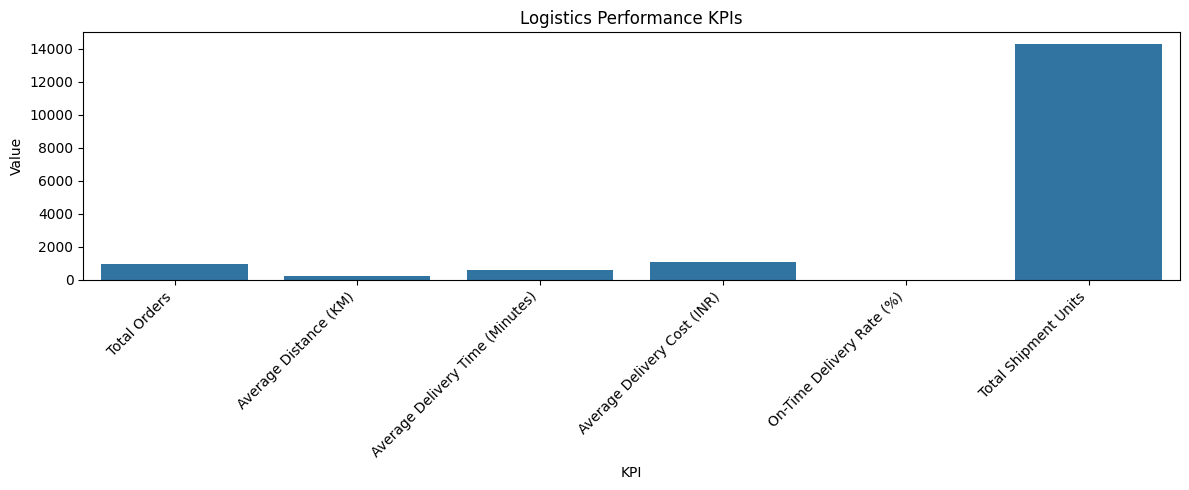

In [ ]:
kpi_df = pd.DataFrame({
    'KPI': list(kpis.keys()),
    'Value': list(kpis.values())
})

plt.figure(figsize=(12, 5))

sns.barplot(
    data=kpi_df,
    x='KPI',
    y='Value'
)

plt.title('Logistics Performance KPIs')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [ ]:
from pathlib import Path

fig_dir = Path('outputs/figures')

fig_dir.mkdir(parents=True, exist_ok=True)

In [ ]:
plt.savefig(
    fig_dir / 'distance_delivery_time.png',
    dpi=300,
    bbox_inches='tight'
)

<Figure size 640x480 with 0 Axes>

In [ ]:
plt.savefig(
    fig_dir / 'correlation_heatmap.png',
    dpi=300,
    bbox_inches='tight'
)

<Figure size 640x480 with 0 Axes>

In [ ]:
import os

print(os.listdir(fig_dir))

['distance_delivery_time.png', 'correlation_heatmap.png']


In [ ]:
with pd.ExcelWriter(
    'Week3_Logistics_Analysis_Results.xlsx'
) as writer:

    summary.to_excel(
        writer,
        sheet_name='Descriptive_Statistics'
    )

    vehicle_perf.to_excel(
        writer,
        sheet_name='Vehicle_Analysis',
        index=False
    )

    traffic_perf.to_excel(
        writer,
        sheet_name='Traffic_Analysis',
        index=False
    )

    weather_perf.to_excel(
        writer,
        sheet_name='Weather_Analysis',
        index=False
    )

    distance_analysis.to_excel(
        writer,
        sheet_name='Distance_Analysis',
        index=False
    )

    volume_analysis.to_excel(
        writer,
        sheet_name='Shipment_Volume',
        index=False
    )

    monthly_analysis.to_excel(
        writer,
        sheet_name='Monthly_Analysis',
        index=False
    )

    correlation_matrix.to_excel(
        writer,
        sheet_name='Correlation'
    )

    kpi_df.to_excel(
        writer,
        sheet_name='KPI_Summary',
        index=False
    )

In [ ]:
from google.colab import files

files.download('Week3_Logistics_Analysis_Results.xlsx')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>